# Karyotype inference and simulated C-banding/FISH for *Capra hircus*

Inputs: frozen tables in `data/input_from_repo1/` (see `SOURCE.md`). Everything cytogenetic here is **simulated**. Assumptions: `docs/ASSUMPTIONS.md`.

| Stage | Question |
|---|---|
| 1. Inference | Q1: what karyotype and heteromorphisms does the sequence predict? |
| 2. Robustness | Q2: how far can it be trusted? |
| 3. Simulation | Q3: which design would detect them? |

## 0. Setup and input checks

In [1]:
import hashlib, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
IN, OUT, FIG = ROOT/'data/input_from_repo1', ROOT/'data/outputs', ROOT/'figures'
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)

# the inputs must be byte-identical to what SOURCE.md records
expected = dict(re.findall(r'\| (\S+\.(?:csv|json)) \| ([0-9a-f]{64}) \|', (IN/'SOURCE.md').read_text()))
for name, sha in expected.items():
    assert hashlib.sha256((IN/name).read_bytes()).hexdigest() == sha, f'checksum mismatch: {name}'
print(len(expected), 'input files verified')

6 input files verified


In [2]:
# One table with the same columns for the five haplotypes.
# IMCG (T2T, P, M) come from centromeres_master.csv; Kiko x Saanen from their own files.
master = pd.read_csv(IN/'centromeres_master.csv').rename(columns={'centromere_side': 'side'})
parts = [master]
for h in ('KikoP', 'SaanenM'):
    parts.append(pd.read_csv(IN/f'{h}_centromeres.csv'))
cols = ['hap', 'chr', 'kind', 'length', 'side', 'cen_start', 'cen_end', 'cen_len', 'sat_bp', 'sat_frac', 'complete', 'low_satellite']
H = pd.concat([p[cols] for p in parts], ignore_index=True)
H['complete'] = H.complete.astype(bool); H['low_satellite'] = H.low_satellite.astype(bool)

# Blocks that are not used as ground truth anywhere (see SOURCE.md and docs/ASSUMPTIONS.md)
H['excluded'] = H.low_satellite | ~H.complete | ((H.hap == 'SaanenM') & (H.chr == 'CHI5'))
# Blocks kept but marked: large SatI expansions of uncertain origin (real, or an assembler duplication)
DOUBTFUL = {('KikoP', 'CHI14'), ('SaanenM', 'CHI7'), ('SaanenM', 'CHI15')}
H['doubtful'] = [(a, b) in DOUBTFUL for a, b in zip(H.hap, H.chr)]
H['chr_n'] = H.chr.str.replace('CHI', '').replace({'X': '30'}).astype(int)
H.groupby('hap').agg(chromosomes=('chr', 'size'), excluded=('excluded', 'sum'), doubtful=('doubtful', 'sum'))

,chromosomes,excluded,doubtful
hap,,,
KikoP,30,0,1
M,30,8,0
P,29,9,0
SaanenM,30,1,2
T2T,30,0,0


## 1. Inference (Q1)

### 1a. Karyotype table

For each chromosome and haplotype:
- **Relative length**: percent of the summed length of the 29 autosomes of that haplotype (the X is expressed on the same base, so it is comparable across haplotypes even where the X is absent from the assembly).
- **Centromere position**: the middle of the satellite block, measured from the satellite end (the tables are already in that frame: `cen_start` is the distance from that end, and `side` only says whether it is the left or the right end of the deposited sequence). Because the block is a domain of several Mb and not a point, this is an approximation. The distance from the end to the start of the block is kept too.
- **Centromeric index** = short arm / length, **arm ratio** r = long arm / short arm, and the class of Levan et al. (1964): r = 1.0-1.7 metacentric, 1.7-3.0 submetacentric, 3.0-7.0 subterminal, above 7.0 terminal.

In a goat all the autosomes and the X are acrocentric, so the classes carry almost no information. The table is here to check that, and to show the X, the only chromosome with a real short arm.

In [3]:
def levan(r):
    return 'm' if r < 1.7 else 'sm' if r < 3.0 else 'st' if r < 7.0 else 't'

K = H.copy()
# cen_start / cen_end are measured from the satellite end of the chromosome (oriented frame), in every assembly:
# 'side' only records which end of the *deposited* sequence that is (L or R), so it is not used here.
# (the only autosome block that starts farther is P-CHI28, a 0.25-Mb fragment of an incomplete block, already excluded)
assert (K[(K.kind == 'autosome') & ~K.excluded].cen_start < 0.1e6).all(), 'usable autosome blocks should start within 0.1 Mb of the end'
mid = (K.cen_start + K.cen_end) / 2
K['p_to_start'] = K.cen_start                                                       # end -> start of the block
K['p'] = mid                                                                        # end -> middle of the block
K['q'] = K.length - K.p
K['CI'] = K.p / K.length
K['arm_ratio'] = K.q / K.p
K['levan'] = K.arm_ratio.map(levan)
auto_sum = K[K.kind == 'autosome'].groupby('hap').length.sum()
K['rel_length_pct'] = 100 * K.length / K.hap.map(auto_sum)
K['rank_by_size'] = K.groupby('hap').length.rank(ascending=False).astype(int)
for c in ('length', 'cen_start', 'cen_end', 'cen_len', 'p', 'p_to_start'):
    K[c + '_Mb'] = K[c] / 1e6

karyotype = K[['hap', 'chr', 'kind', 'length_Mb', 'rel_length_pct', 'rank_by_size', 'side', 'cen_len_Mb',
               'p_to_start_Mb', 'p_Mb', 'CI', 'arm_ratio', 'levan', 'complete', 'low_satellite', 'excluded', 'doubtful']]
karyotype.round(4).to_csv(OUT/'karyotype_inferred.csv', index=False)

summ = karyotype.groupby(['hap', 'kind']).agg(n=('chr', 'size'), CI_min=('CI', 'min'), CI_max=('CI', 'max'),
                                              arm_ratio_min=('arm_ratio', 'min'),
                                              classes=('levan', lambda s: dict(s.value_counts()))).round(3)
summ

n  CI_min  CI_max  arm_ratio_min    classes
hap     kind                                                  
KikoP   X          1   0.052   0.052         18.234   {'t': 1}
        autosome  29   0.023   0.072         12.841  {'t': 29}
M       X          1   0.053   0.053         17.891   {'t': 1}
        autosome  29   0.006   0.082         11.168  {'t': 29}
P       autosome  29   0.018   0.087         10.469  {'t': 29}
SaanenM X          1   0.053   0.053         17.880   {'t': 1}
        autosome  29   0.021   0.087         10.541  {'t': 29}
T2T     X          1   0.053   0.053         17.891   {'t': 1}
        autosome  29   0.021   0.082         11.187  {'t': 29}

In [4]:
t = karyotype[karyotype.hap == 'T2T'].set_index('chr')
print('T2T size order (top 5):', ', '.join(f'{c} {r:.2f} %' for c, r in t.rel_length_pct.nlargest(5).items()))
print('T2T X: short arm (end -> middle of block) = %.2f Mb, CI = %.3f, arm ratio = %.1f, end -> start of block = %.2f Mb'
      % (t.loc['CHIX', 'p_Mb'], t.loc['CHIX', 'CI'], t.loc['CHIX', 'arm_ratio'], t.loc['CHIX', 'p_to_start_Mb']))
a = t[t.kind == 'autosome']
print('T2T autosomes: end -> start of block up to %.3f Mb; end -> middle of block %.2f-%.2f Mb' % (a.p_to_start_Mb.max(), a.p_Mb.min(), a.p_Mb.max()))

T2T size order (top 5): CHI1 6.17 %, CHI2 5.47 %, CHIX 5.36 %, CHI3 4.92 %, CHI5 4.74 %
T2T X: short arm (end -> middle of block) = 7.66 Mb, CI = 0.053, arm ratio = 17.9, end -> start of block = 7.23 Mb
T2T autosomes: end -> start of block up to 0.047 Mb; end -> middle of block 1.97-5.23 Mb


### 1b. Idiogram

The 30 chromosomes of T2T-goat2.0, in order of size, drawn to scale. The satellite block is the shaded part; it is what a C-band would be expected to mark. The block is the operational centromere of the sequence repository (satellite domain, not CENP-A), so this is a map of where heterochromatin could be, not a prediction of a real band.

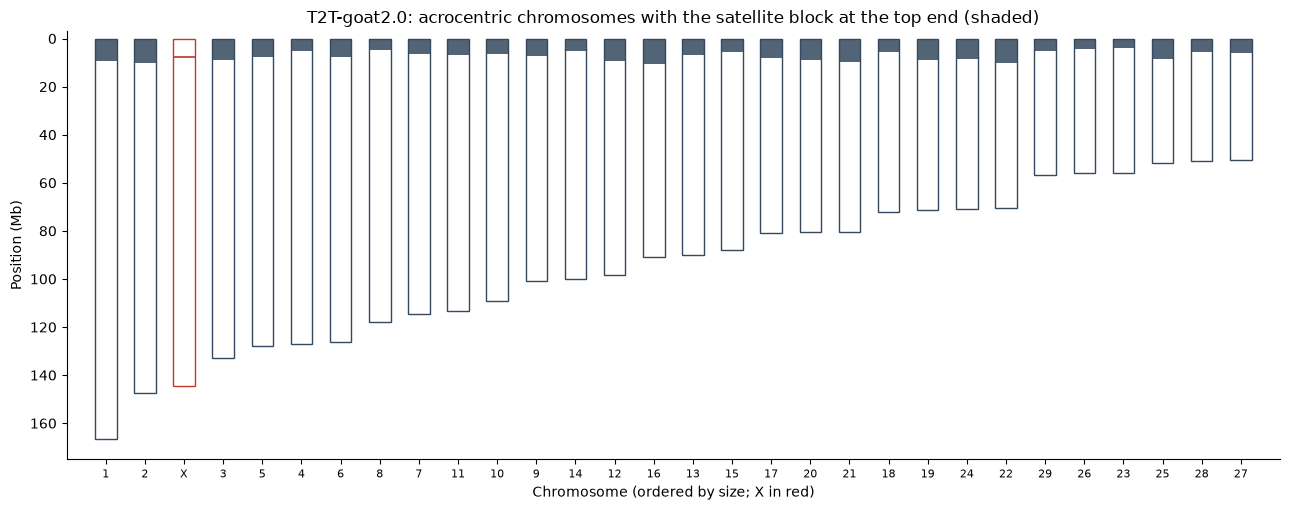

In [5]:
t = karyotype[karyotype.hap == 'T2T'].sort_values('length_Mb', ascending=False).reset_index(drop=True)
Kt = K[K.hap == 'T2T'].set_index('chr')
fig, ax = plt.subplots(figsize=(13, 5.2))
w = 0.55
for i, r in t.iterrows():
    L = r.length_Mb; s, e = Kt.loc[r.chr, 'cen_start_Mb'], Kt.loc[r.chr, 'cen_end_Mb']
    col = '#c0392b' if r.chr == 'CHIX' else '#34495e'
    ax.add_patch(plt.Rectangle((i - w/2, 0), w, L, fc='white', ec=col, lw=1))
    ax.add_patch(plt.Rectangle((i - w/2, s), w, e - s, fc=col, alpha=.85, lw=0))   # satellite block (left end of the sequence)
ax.set_xlim(-1, len(t)); ax.set_ylim(175, -3)                                      # ends at the top = start of the sequence
ax.set_xticks(range(len(t))); ax.set_xticklabels(t.chr.str.replace('CHI', ''), fontsize=8)
ax.set_xlabel('Chromosome (ordered by size; X in red)'); ax.set_ylabel('Position (Mb)')
ax.set_title('T2T-goat2.0: acrocentric chromosomes with the satellite block at the top end (shaded)')
for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
plt.tight_layout(); fig.savefig(FIG/'idiogram_T2T.png', dpi=150); plt.show()

### 1c. Expected heteromorphisms

A heteromorphism here is a difference in the size of the block between the two homologs of a pair. Two pairs of haplotypes are used, kept separate:

- **IMCG P / M**: the two haplotypes of one animal (the male of the reference assembly). The X is not in P, so there are 29 autosome pairs at most.
- **KikoP / SaanenM**: the two haplotypes of an F1 female whose parents are of two breeds, so the difference mixes individual and breed. It is labelled "between breeds", not "within an animal".

The measure is d = |ln(block_a / block_b)|, and the absolute difference in Mb. A pair is usable only if both blocks are complete and not `low_satellite`, and Saanen CHI5 is left out. Pairs that include a doubtful block are kept and marked.

The size classes are conventions of this analysis, not of nature: d < 0.18 small (below about 20 %, the same threshold that the simulation will use as the definition of a true heteromorphism), 0.18-0.50 moderate, above 0.50 large.

In [6]:
PAIRS = {'IMCG P / M': ('P', 'M', 'within IMCG'), 'KikoP / SaanenM': ('KikoP', 'SaanenM', 'between breeds (Kiko x Saanen)')}
S = K.set_index(['hap', 'chr'])
rows = []
for name, (a, b, label) in PAIRS.items():
    for chrom in sorted(set(S.loc[a].index) & set(S.loc[b].index), key=lambda c: int(c.replace('CHI', '').replace('X', '30'))):
        ra, rb = S.loc[(a, chrom)], S.loc[(b, chrom)]
        rows.append(dict(pair=name, comparison=label, chr=chrom, kind=ra.kind,
                         cen_a_Mb=ra.cen_len_Mb, cen_b_Mb=rb.cen_len_Mb,
                         abs_diff_Mb=abs(ra.cen_len - rb.cen_len) / 1e6,
                         d_cen=abs(np.log(ra.cen_len / rb.cen_len)),
                         d_rest=abs(np.log((ra.length - ra.cen_len) / (rb.length - rb.cen_len))),
                         usable=not (ra.excluded or rb.excluded),
                         doubtful=bool(ra.doubtful or rb.doubtful),
                         why_not=', '.join(f'{h} {c}: ' + ('low_satellite' if S.loc[(h, c)].low_satellite else 'gap/incomplete' if not S.loc[(h, c)].complete else 'cut by window')
                                           for h, c in ((a, chrom), (b, chrom)) if S.loc[(h, c)].excluded)))
het = pd.DataFrame(rows)
het['size_class'] = np.where(~het.usable, 'excluded', pd.cut(het.d_cen, [-1, .18, .5, 99], labels=['small', 'moderate', 'large']).astype(str))
het.round(4).to_csv(OUT/'expected_heteromorphisms.csv', index=False)

u = het[het.usable]
summary = u.groupby('pair').agg(n_usable=('chr', 'size'), n_doubtful=('doubtful', 'sum'),
                                median_d_cen=('d_cen', 'median'), median_d_rest=('d_rest', 'median'),
                                median_abs_diff_Mb=('abs_diff_Mb', 'median'),
                                small=('size_class', lambda s: (s == 'small').sum()),
                                moderate=('size_class', lambda s: (s == 'moderate').sum()),
                                large=('size_class', lambda s: (s == 'large').sum())).round(3)
summary

,n_usable,n_doubtful,median_d_cen,median_d_rest,median_abs_diff_Mb,small,moderate,large
pair,,,,,,,,
IMCG P / M,16,0,0.371,0.001,2.671,5,6,5
KikoP / SaanenM,29,3,0.165,0.002,1.088,17,11,1


In [7]:
print('Excluded or not comparable:')
print(het[~het.usable][['pair', 'chr', 'why_not']].to_string(index=False))
print()
print('Usable pairs that include a doubtful block:')
print(het[het.usable & het.doubtful][['pair', 'chr', 'cen_a_Mb', 'cen_b_Mb', 'd_cen', 'size_class']].round(2).to_string(index=False))

Excluded or not comparable:
           pair   chr                                          why_not
     IMCG P / M  CHI2   P CHI2: gap/incomplete, M CHI2: gap/incomplete
     IMCG P / M  CHI4                           P CHI4: gap/incomplete
     IMCG P / M  CHI7                            M CHI7: low_satellite
     IMCG P / M  CHI9                            M CHI9: low_satellite
     IMCG P / M CHI10 P CHI10: gap/incomplete, M CHI10: gap/incomplete
     IMCG P / M CHI11                          P CHI11: gap/incomplete
     IMCG P / M CHI17                          P CHI17: gap/incomplete
     IMCG P / M CHI20                          M CHI20: gap/incomplete
     IMCG P / M CHI22                          M CHI22: gap/incomplete
     IMCG P / M CHI23 P CHI23: gap/incomplete, M CHI23: gap/incomplete
     IMCG P / M CHI27                          P CHI27: gap/incomplete
     IMCG P / M CHI28                          P CHI28: gap/incomplete
     IMCG P / M CHI29  P CHI29: gap/incomplete, M

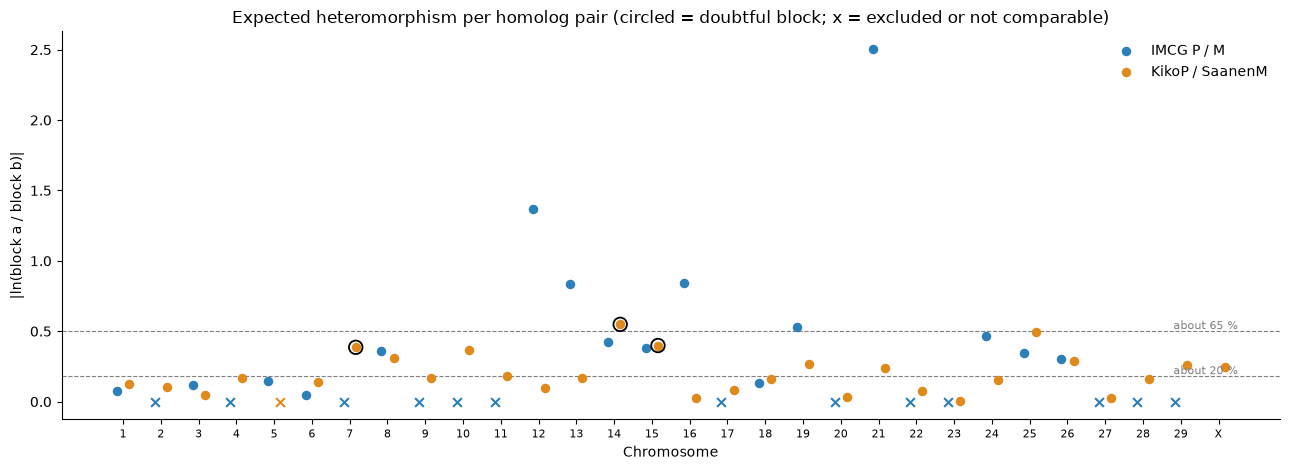

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.8))
order = [f'CHI{i}' for i in range(1, 30)] + ['CHIX']
colors = {'IMCG P / M': '#2c7fb8', 'KikoP / SaanenM': '#e08a1e'}
for k, (name, g) in enumerate(het.groupby('pair')):
    off = (k - .5) * .32
    g = g.set_index('chr').reindex(order)
    ok = g[g.usable.fillna(False).astype(bool)]
    ax.scatter([order.index(c) + off for c in ok.index], ok.d_cen, s=34, color=colors[name], label=name, zorder=3)
    dd = ok[ok.doubtful]
    ax.scatter([order.index(c) + off for c in dd.index], dd.d_cen, s=95, facecolor='none', edgecolor='black', lw=1.3, zorder=4)
    bad = g[g.usable.eq(False)]
    ax.scatter([order.index(c) + off for c in bad.index], [0.0] * len(bad), marker='x', s=40, color=colors[name], zorder=3)
for y, lab in ((.18, 'about 20 %'), (.5, 'about 65 %')):
    ax.axhline(y, color='gray', ls='--', lw=.8); ax.text(len(order) - .5, y + .015, lab, ha='right', fontsize=8, color='gray')
ax.set_xticks(range(len(order))); ax.set_xticklabels([c.replace('CHI', '') for c in order], fontsize=8)
ax.set_xlabel('Chromosome'); ax.set_ylabel('|ln(block a / block b)|')
ax.set_title('Expected heteromorphism per homolog pair (circled = doubtful block; x = excluded or not comparable)')
ax.legend(frameon=False)
for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
plt.tight_layout(); fig.savefig(FIG/'expected_heteromorphisms.png', dpi=150); plt.show()

### What stage 1 says

Read the two tables above together with the figure. The cell below prints the numbers that the README and the next stages quote, taken from the tables and not typed by hand.

In [9]:
t = karyotype[karyotype.hap == 'T2T']
print('Classes in T2T:', {k: int(v) for k, v in t.levan.value_counts().items()})
print('Autosomes: CI from %.3f to %.3f; X: CI = %.3f' % (t[t.kind == 'autosome'].CI.min(), t[t.kind == 'autosome'].CI.max(), t[t.kind == 'X'].CI.iloc[0]))
for name, r in summary.iterrows():
    print(f'{name}: {int(r.n_usable)} usable pairs; median |ln ratio| = {r.median_d_cen:.2f} in the block against {r.median_d_rest:.3f} in the rest; '
          f'median difference {r.median_abs_diff_Mb:.2f} Mb; small/moderate/large = {int(r.small)}/{int(r.moderate)}/{int(r.large)}')

Classes in T2T: {'t': 30}
Autosomes: CI from 0.021 to 0.082; X: CI = 0.053
IMCG P / M: 16 usable pairs; median |ln ratio| = 0.37 in the block against 0.001 in the rest; median difference 2.67 Mb; small/moderate/large = 5/6/5
KikoP / SaanenM: 29 usable pairs; median |ln ratio| = 0.17 in the block against 0.002 in the rest; median difference 1.09 Mb; small/moderate/large = 17/11/1


## 2. Robustness (Q2)

To do: repeat stage 1 without `low_satellite` blocks, Saanen CHI5, and Kiko CHI14 / Saanen CHI7 and CHI15; label each pair firm or doubtful.

## 3. Simulation (Q3)

To do: reuse the earlier simulator with the rebuilt ground truth; vary K, F, optical resolution, error and number of metaphases; report power by size of true difference.